Well use a GenericCascadeCase and we will load the example dataset, generated with OpenFOAM.
We don't necessarily need a complete dataset for postprocessing procedures.

In [12]:
from ntrfc.turbo.cascade_case.solution import GenericCascadeCase
from ntrfc.turbo.cascade_case.post import blade_loading_cp
from ntrfc.turbo.cascade_case.post import blade_loading_absolute
from ntrfc.turbo.cascade_case.post import blade_loading_mais
from ntrfc.turbo.cascade_case.post import compute_avdr_inout_massave
from ntrfc.turbo.cascade_case.post import cascade_case_meshquality
from ntrfc.turbo.cascade_case.post import cascade_case_tux
from ntrfc.turbo.cascade_case.post import cascadecase_contour
from ntrfc.turbo.cascade_case.post import case_cfl


import os
import pyvista as pv
import importlib.resources
from IPython.display import Image


if os.getenv('DISPLAY') is None:
    pv.start_xvfb()  # Start X virtual framebuffer (Xvfb)
    
pv.set_jupyter_backend('trame')

In [13]:

inlet_path =  importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/inlet.vtp"
outlet_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/outlet.vtp"
blade_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/blade_wall.vtp"
fluid_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/internal.vtu"

case = GenericCascadeCase()

case.read_meshes(inlet_path,"inlet")
case.read_meshes(outlet_path,"outlet")
case.read_meshes(blade_path,"blade")
case.read_meshes(fluid_path,"fluid")

case.case_meta.meanvelocity_name="U"
case.case_meta.meanpressure_name="p"
case.case_meta.meandensity_name="rho"
case.case_meta.meanturbulentkineticenergy_name="k"

case.set_bladeslice_midz()

[ntrfc info] working with pv.PolyData, dataarrays can be used for postprocessing


In [14]:
cascadecase_contour(case,"meanvelocity")
cascadecase_contour(case,"meanturbulentkineticenergy")


Widget(value='<iframe src="http://localhost:43965/index.html?ui=P_0x7f9908cb2790_6&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:43965/index.html?ui=P_0x7f9908b55490_7&reconnect=auto" class="pyvi…

'/tmp/tmpvyaq8kxc/contour_meanturbulentkineticenergy.png'

In [15]:
case.blade.plot(window_size=[800, 800])

Widget(value='<iframe src="http://localhost:43965/index.html?ui=P_0x7f9908b54310_8&reconnect=auto" class="pyvi…

'/tmp/tmpt1x4csg_/plot.png'

[ntrfc info] computing aspect ratios...
[ntrfc info] meshquality AspectRatio: OK
[ntrfc info] computing skewnesses...
[ntrfc info] meshquality Skewness: BAD
[ntrfc info] computing expansion factors...


/home/many/PycharmProjects/NTRfC/ntrfc/meshquality/skewness.py:34: UserWarning: [ntrfc warning] Mesh quality (Skewness) is bad, consider refining the mesh.
  warnings.warn(f"[ntrfc warning] Mesh quality ({qualityname}) is bad, consider refining the mesh.")


[ntrfc info] meshquality MeshExpansion: OK


Widget(value='<iframe src="http://localhost:43965/index.html?ui=P_0x7f995db92710_9&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:43965/index.html?ui=P_0x7f995f02b010_10&reconnect=auto" class="pyv…

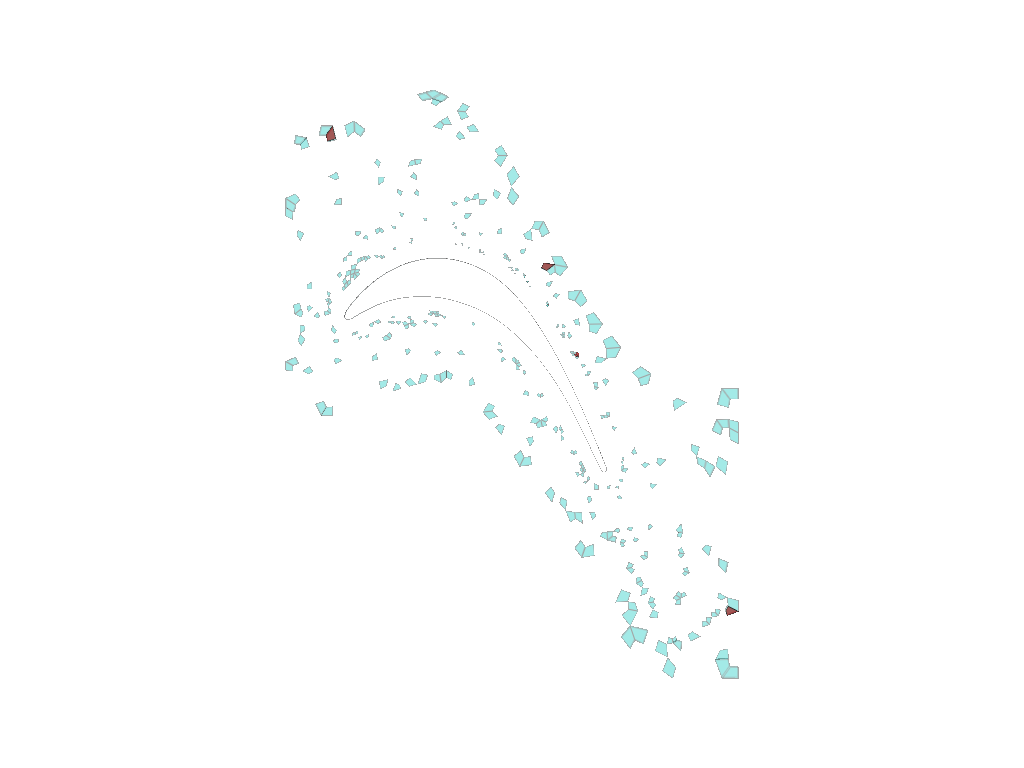

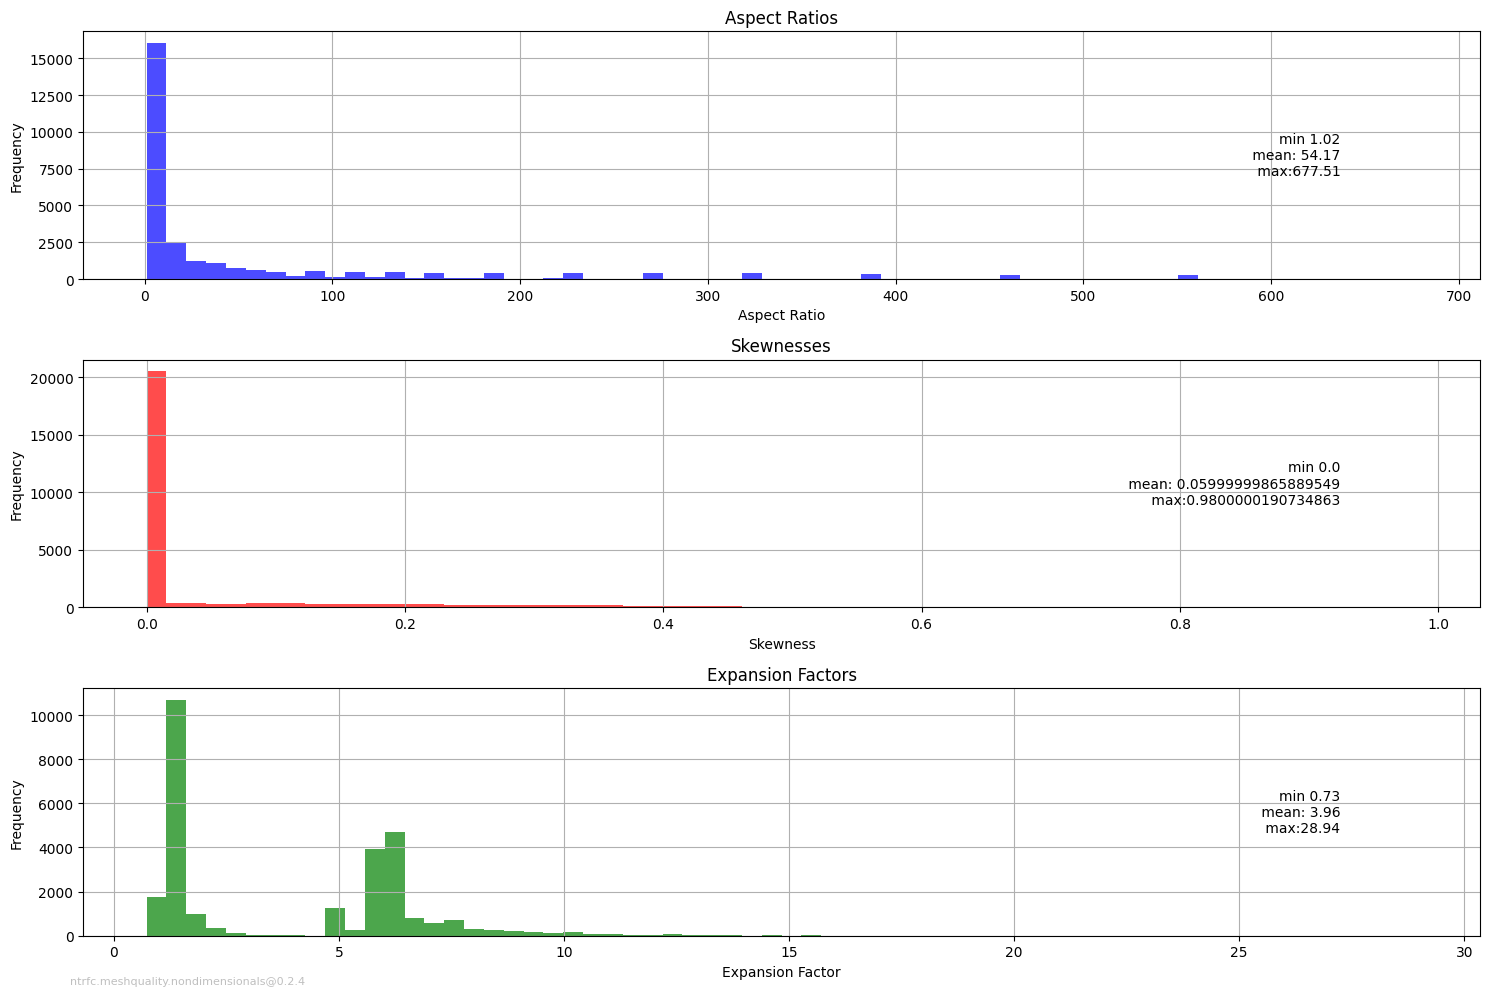

In [16]:
figpath_qualitystats, figpath_meshslice, figpath_badcells, pdfpath_qualityreport = cascade_case_meshquality(case)
# plot quality figures
Image(figpath_qualitystats, width=400, height=400)
# plot mesh slice
Image(figpath_meshslice, width=400, height=400)
# plot bad cells
Image(figpath_badcells, width=400, height=400)

[ntrfc info] writing blade loading statistics


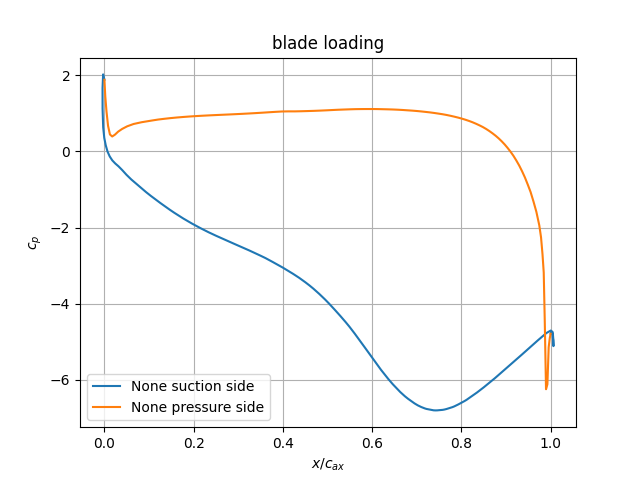

In [17]:
fig= blade_loading_cp(case)
Image(fig, width=400, height=400)

[ntrfc info] writing blade loading statistics


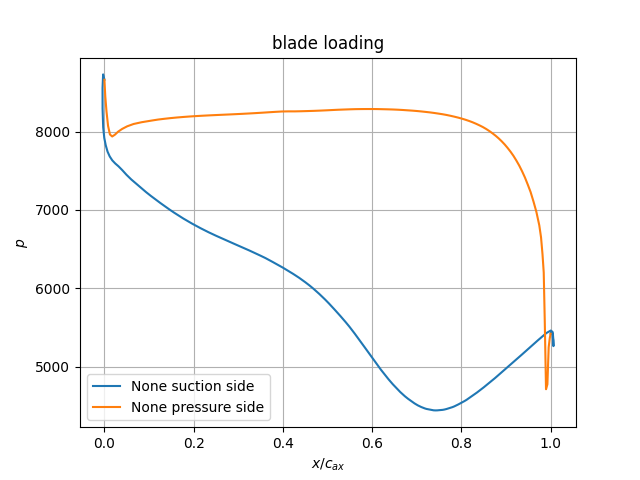

In [18]:
fig = blade_loading_absolute(case)
Image(fig, width=400, height=400)

In [19]:
avdr =compute_avdr_inout_massave(case)
print(avdr)

2.6096333644205414


[ntrfc info] writing blade loading statistics


/home/many/PycharmProjects/NTRfC/ntrfc/fluid/isentropic.py:36: RuntimeWarning: invalid value encountered in sqrt
  y = np.sqrt(2 / (kappa - 1) * ((p_frestream / p_blade) ** ((kappa - 1) / kappa) - 1))


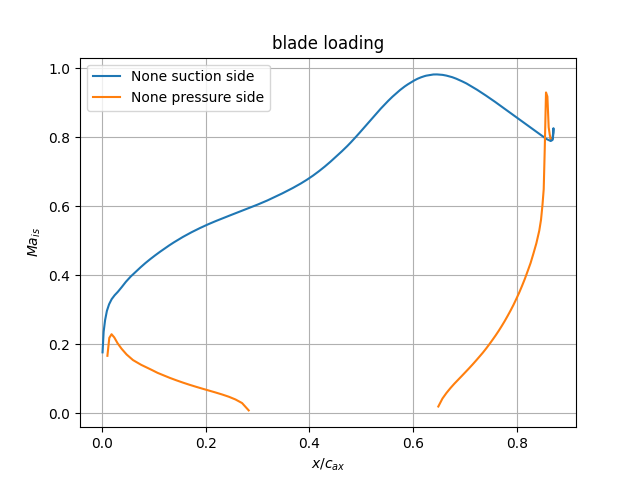

In [20]:
fig= blade_loading_mais(case)
Image(fig, width=400, height=400)

100%|██████████| 200/200 [00:01<00:00, 137.43it/s]


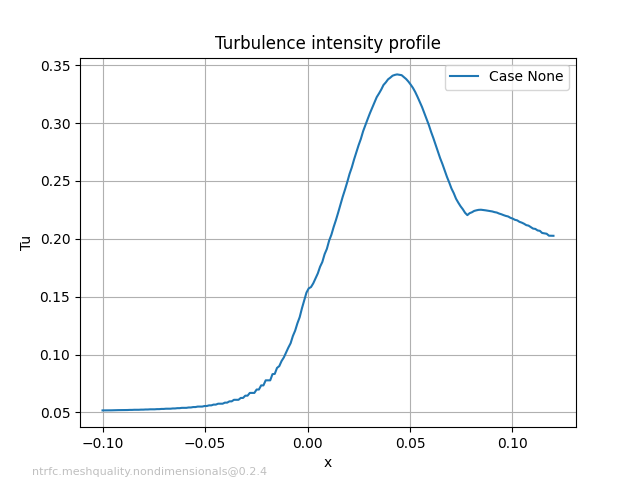

In [21]:
fig = cascade_case_tux(case)
Image(fig, width=400, height=400)

100%|██████████| 28062/28062 [06:33<00:00, 71.39it/s] 


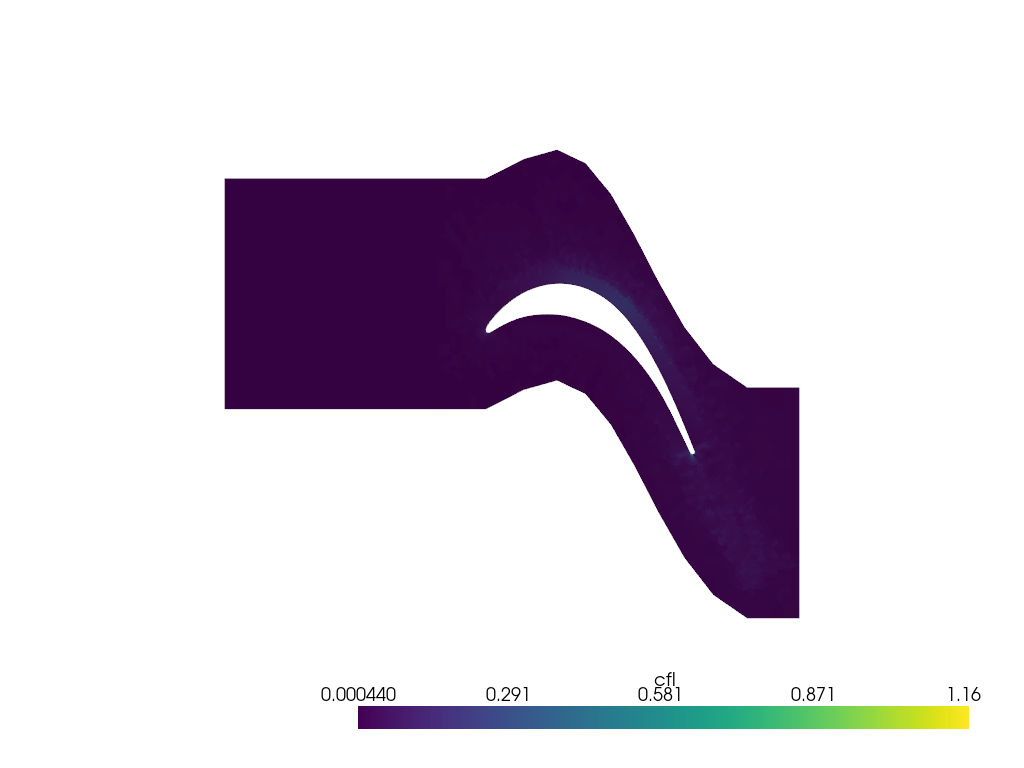

In [24]:
case.case_meta.dt = 3.4e-7
fig = case_cfl(case)

Image(fig, width=400, height=400)